## Дискретне перетворення Фурʼє

In [2]:
import numpy as np
import matplotlib.pyplot as plt

from thinkdsp import decorate
PI2 = 2 * np.pi

In [3]:
# suppress scientific notation for small numbers
np.set_printoptions(precision=3, suppress=True)

## Комплексна синусоїда

Це визначення класу ComplexSinusoid з методами друку для відображення проміжних результатів

In [4]:
from thinkdsp import Sinusoid

class ComplexSinusoid(Sinusoid):
    """Represents a complex exponential signal."""
    
    def evaluate(self, ts):
        """Evaluates the signal at the given times.

        ts: float array of times
        
        returns: float wave array
        """
        print(ts)
        phases = PI2 * self.freq * ts + self.offset
        print(phases)
        ys = self.amp * np.exp(1j * phases)
        return ys

Ось приклад:

In [5]:
signal = ComplexSinusoid(freq=1, amp=0.6, offset=1)
wave = signal.make_wave(duration=1, framerate=4)
print(wave.ys)

[0.   0.25 0.5  0.75]
[1.    2.571 4.142 5.712]
[ 0.324+0.505j -0.505+0.324j -0.324-0.505j  0.505-0.324j]


Найпростіший спосіб синтезувати суміш сигналів – це обчислити сигнали та додати їх.

In [6]:
from thinkdsp import SumSignal

def synthesize1(amps, freqs, ts):
    components = [ComplexSinusoid(freq, amp)
                  for amp, freq in zip(amps, freqs)]
    signal = SumSignal(*components)
    ys = signal.evaluate(ts)
    return ys

Ось приклад сигналу, що складається з 4 синусоїд:

In [7]:
amps = np.array([0.6, 0.25, 0.1, 0.05])
freqs = [100, 200, 300, 400]
framerate = 11025

ts = np.linspace(0, 1, framerate, endpoint=False)
ys = synthesize1(amps, freqs, ts)
print(ys)

[0. 0. 0. ... 1. 1. 1.]
[  0.      0.057   0.114 ... 628.148 628.205 628.262]
[0. 0. 0. ... 1. 1. 1.]
[   0.       0.114    0.228 ... 1256.295 1256.409 1256.523]
[0. 0. 0. ... 1. 1. 1.]
[   0.       0.171    0.342 ... 1884.443 1884.614 1884.785]
[0. 0. 0. ... 1. 1. 1.]
[   0.       0.228    0.456 ... 2512.59  2512.818 2513.046]
[1.   +0.j    0.995+0.091j 0.979+0.18j  ... 0.953-0.267j 0.979-0.18j
 0.995-0.091j]


Побудуємо графіки дійсної та уявної частин сигналу:

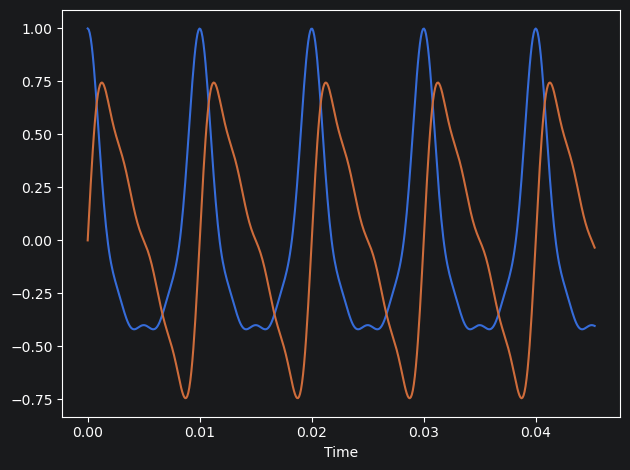

In [8]:
n = 500
plt.plot(ts[:n], ys[:n].real)
plt.plot(ts[:n], ys[:n].imag)
decorate(xlabel='Time')

Дійсна частина — це суміш косинусів; уявна частина — це суміш синусів.
Вони містять однакові частотні компоненти з однаковими амплітудами,
тому звучать для нас однаково:

In [9]:
from thinkdsp import Wave

wave = Wave(ys.real, framerate)
wave.apodize()
wave.make_audio()

In [10]:
wave = Wave(ys.imag, framerate)
wave.apodize()
wave.make_audio()

Ми можемо виразити ті самі дії як матричне множення

In [11]:
def synthesize2(amps, freqs, ts):
    args = np.outer(ts, freqs)
    M = np.exp(1j * PI2 * args)
    ys = np.dot(M, amps)
    return ys

І результат буде звучати так само.

In [12]:
amps = np.array([0.6, 0.25, 0.1, 0.05])
ys = synthesize2(amps, freqs, ts)
print(ys)

[1.   +0.j    0.995+0.091j 0.979+0.18j  ... 0.953-0.267j 0.979-0.18j
 0.995-0.091j]


In [13]:
wave = Wave(ys.real, framerate)
wave.apodize()
wave.make_audio()

Щоб побачити вплив комплексної амплітуди, ми можемо повернути амплітуди на 1,5 радіана:

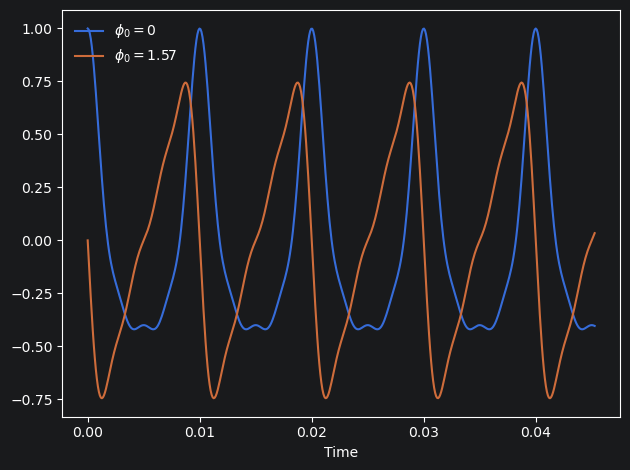

In [14]:
phi = np.pi/2
amps2 = amps * np.exp(1j * phi)
ys2 = synthesize2(amps2, freqs, ts)

n = 500
plt.plot(ts[:n], ys.real[:n], label=r'$\phi_0 = 0$')
plt.plot(ts[:n], ys2.real[:n], label=r'$\phi_0 = 1.57$')
decorate(xlabel='Time')

Поворот усіх компонентів на однакове фазове зміщення змінює форму сигналу, оскільки компоненти мають різні періоди, тому однакове зміщення має різний вплив на кожен компонент.

### Аналіз

Найпростіший спосіб аналізу сигналу, тобто знаходження амплітуди для кожного компонента,
полягає у створенні такої ж матриці, яку ми використовували для синтезу,
а потім у розв'язанні системи лінійних рівнянь.

In [15]:
def analyze1(ys, freqs, ts):
    args = np.outer(ts, freqs)
    M = np.exp(1j * PI2 * args)
    amps = np.linalg.solve(M, ys)
    return amps

Використовуючи перші 4 значення з хвильового масиву, ми можемо відновити амплітуди.

In [16]:
n = len(freqs)
amps2 = analyze1(ys[:n], freqs, ts[:n])
print(amps2.real)

[0.6  0.25 0.1  0.05]


Якщо ми визначимо `freqs` від $0$ до $N-1$ та `ts` від $0$ до $(N-1)/N$,
ми отримаємо унітарну матрицю.

In [17]:
N = 4
ts = np.arange(N) / N
freqs = np.arange(N)
args = np.outer(ts, freqs)
M = np.exp(1j * PI2 * args)
print(M)

[[ 1.+0.j  1.+0.j  1.+0.j  1.+0.j]
 [ 1.+0.j  0.+1.j -1.+0.j -0.-1.j]
 [ 1.+0.j -1.+0.j  1.-0.j -1.+0.j]
 [ 1.+0.j -0.-1.j -1.+0.j  0.+1.j]]


Щоб перевірити, чи є матриця унітарною, ми можемо обчислити $M^*\cdot M$,
де $M^*$ -- ермітово-спряжена матриця. Для унітарної матриці результатом
множення має бути одинична матриця. Маємо:

In [18]:
MstarM = M.conj().transpose().dot(M)
print(MstarM.real)

[[ 4. -0.  0.  0.]
 [-0.  4. -0.  0.]
 [ 0. -0.  4. -0.]
 [ 0.  0. -0.  4.]]


Результат насправді становить $4 I$, де $4 = N$, порядку матриці,
тому загалом нам потрібно враховувати додатковий коефіцієнт $N$,
але це проблема.

Ми можемо використати цей результат для написання швидшої версії `analyze1`:

In [19]:
def analyze2(ys, freqs, ts):
    args = np.outer(ts, freqs)
    M = np.exp(1j * PI2 * args)
    amps = M.conj().transpose().dot(ys) / N
    return amps

In [53]:
N = 4
amps = np.array([0.6, 0.25, 0.1, 0.05])
freqs = np.arange(N)
ts = np.arange(N) / N
ys = synthesize2(amps, freqs, ts)

amps3 = analyze2(ys, freqs, ts)
print(amps3.real)

[0.6  0.25 0.1  0.05]


Тепер ми можемо написати власну версію DFT (ДПФ -- Дискретного Перетворення Фурʼє):

In [56]:
def synthesis_matrix(N):
    ts = np.arange(N) / N
    freqs = np.arange(N)
    args = np.outer(ts, freqs)
    M = np.exp(1j * PI2 * args)
    return M

In [22]:
def dft(ys):
    N = len(ys)
    M = synthesis_matrix(N)
    amps = M.conj().transpose().dot(ys)
    return amps

І порівняємо результат із `analyze2`:

In [60]:
print(dft(ys).real)

[2.4 1.  0.4 0.2]


Результат близький до `amps * 4`.

Ми також можемо порівняти це з `np.fft.fft`. FFT розшифровується як швидке перетворення
Фур'є (Fast Fourier Transform), що є ще швидшою реалізацією DFT.

In [24]:
print(np.fft.fft(ys))

[2.4+0.j 1. -0.j 0.4-0.j 0.2-0.j]


Обернене ДПФ майже те саме, за винятком того, що нам не потрібно транспонувати $M$,
а потрібно ділити на $N$.

In [61]:
def idft(amps):
    N = len(amps)
    M = synthesis_matrix(N)
    ys = M.dot(amps) / N
    return ys

Ми можемо підтвердити, що `dft(idft(amps))` повертає `amps`:

In [63]:
ys = idft(amps)
print(dft(ys).real)

[0.6  0.25 0.1  0.05]


### Дійсні сигнали

Давайте подивимося, що станеться, якщо застосувати ДПФ до сигналу з дійсним значенням. Використаємо для прикладу пилкоподібний сигнал з основною частотою 500 Гц

In [68]:
from thinkdsp import SawtoothSignal

framerate = 10000
signal = SawtoothSignal(freq=500)
wave = signal.make_wave(duration=0.5, framerate=framerate)
wave.make_audio()

`wave` є 500 Hz пилкоподібним сигналом, дискретизованим із частотою 10 kHz.

In [69]:
hs = dft(wave.ys)
len(wave.ys), len(hs)

(5000, 5000)

`hs` – це ДПФ цієї хвилі, а `amps` містить амплітуди.

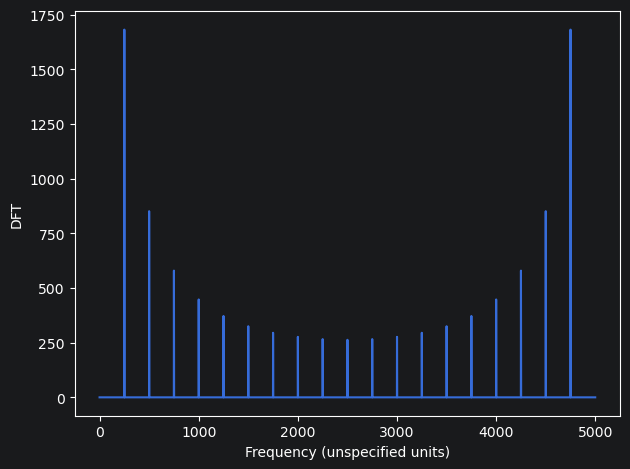

In [70]:
amps = np.abs(hs)
plt.plot(amps)
decorate(xlabel='Frequency (unspecified units)', ylabel='DFT')

ДПФ припускає, що частота дискретизації становить N на одиницю часу для довільної одиниці часу. Нам потрібно перетворити її на фактичні одиниці – секунди – ось так:

In [71]:
N = len(hs)
fs = np.arange(N) * framerate / N

Також ДПФ дійсного сигналу симетричне, тому права частина є надлишковою. Зазвичай ми обчислюємо та будуємо графік лише першої половини:

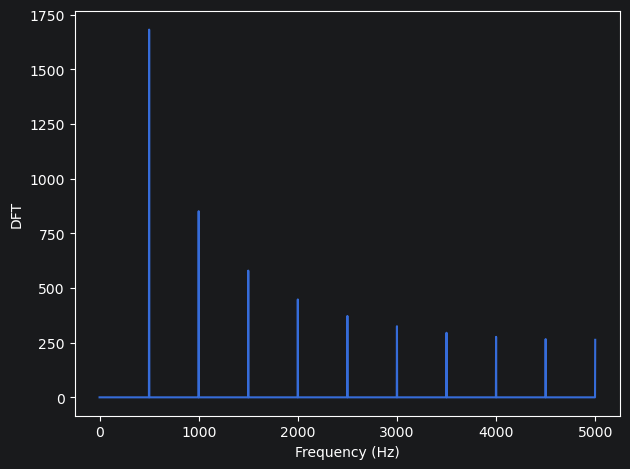

In [72]:
plt.plot(fs[:N//2+1], amps[:N//2+1])
decorate(xlabel='Frequency (Hz)', ylabel='DFT')

Давайте краще зрозуміємо, чому ДПФ дійсного сигналу є симетричним. Я почну зі створення оберненої матриці ДПФ для $N=8$.

In [73]:
M = synthesis_matrix(N=8)

DFT матриця:

In [74]:
Mstar = M.conj().transpose()

І трикутний вейв із 8 елементів:

In [75]:
from thinkdsp import TriangleSignal

wave = TriangleSignal(freq=1).make_wave(duration=1, framerate=8)
wave.ys

array([ 1. ,  0.5,  0. , -0.5, -1. , -0.5,  0. ,  0.5])

Ось як він виглядає

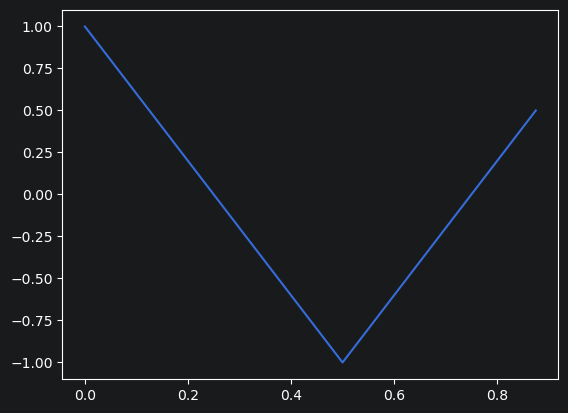

In [76]:
wave.plot()

Тепер поглянемо на рядки 3 і 5 матриці DFT

In [77]:
row3 = Mstar[3, :]
print(row3)

[ 1.   -0.j    -0.707-0.707j -0.   +1.j     0.707-0.707j -1.   -0.j
  0.707+0.707j  0.   -1.j    -0.707+0.707j]


In [78]:
row5 = Mstar[5, :]
row5

array([ 1.   -0.j   , -0.707+0.707j,  0.   -1.j   ,  0.707+0.707j,
       -1.   -0.j   ,  0.707-0.707j, -0.   +1.j   , -0.707-0.707j])

Вони майже однакові, але row5 є комплексно-спряженим до row3.

In [79]:
def approx_equal(a, b, tol=1e-10):
    return np.sum(np.abs(a-b)) < tol

In [39]:
approx_equal(row3, row5.conj())

np.True_

Коли ми помножимо матрицю DFT на хвильовий масив, елемент з індексом 3 буде таким:

In [81]:
X3 = row3.dot(wave.ys)
X3

np.complex128(0.5857864376269055-1.1102230246251565e-16j)

А елемент з індексом 5:

In [82]:
X5 = row5.dot(wave.ys)
X5

np.complex128(0.5857864376269062-4.996003610813204e-16j)

Вони однакові з точністю до похибок обчилення

In [83]:
abs(X3 - X5)

np.float64(7.711855592701269e-16)

Зробимо те саме із комплексним сигналом:

[0.    0.125 0.25  0.375 0.5   0.625 0.75  0.875]
[0.    0.785 1.571 2.356 3.142 3.927 4.712 5.498]


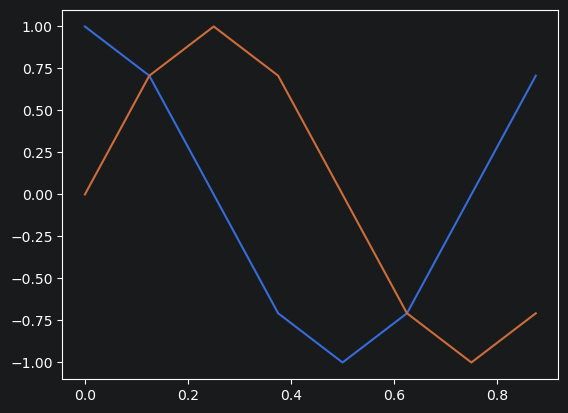

In [84]:
wave2 = ComplexSinusoid(freq=1).make_wave(duration=1, framerate=8)
plt.plot(wave2.ts, wave2.ys.real)
plt.plot(wave2.ts, wave2.ys.imag)

Тепер елементи з індексами 3 та 5 відрізняються:

In [85]:
X3 = row3.dot(wave2.ys)
X3

np.complex128(1.3355903570701533e-15-2.321911412826009e-16j)

In [86]:
X5 = row5.dot(wave2.ys)
X5

np.complex128(-2.00739765020948e-16+4.585702409165418e-16j)

Візуально ми можемо підтвердити, що ШПФ дійсного сигналу є симетричним:

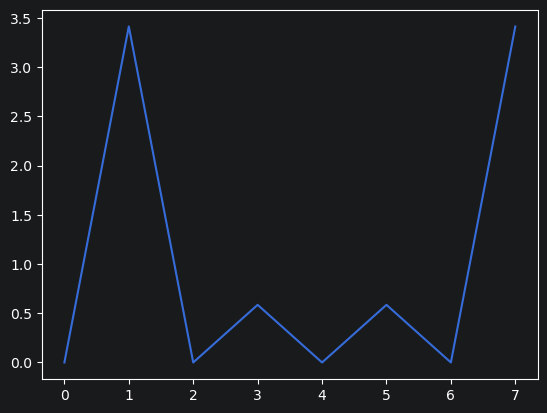

In [87]:
hs = np.fft.fft(wave.ys)
plt.plot(abs(hs))

А FFT комплексного сигналу не є симетричним:

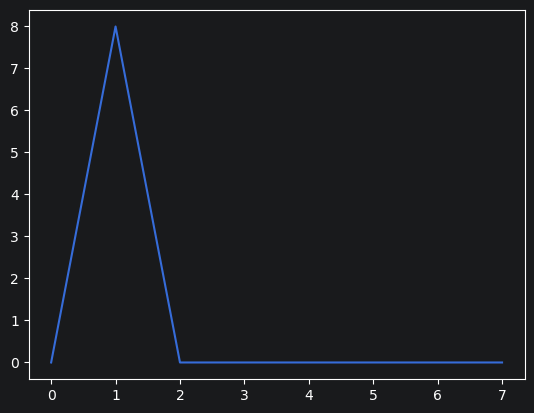

In [88]:
hs = np.fft.fft(wave2.ys)
plt.plot(abs(hs))

Інший спосіб подумати про все це – обчислити матрицю ДПФ для різних частот. Замість $0$ до $N-1$, спробуємо $0, 1, 2, 3, 4, -3, -2, -1$.

In [89]:
N = 8
ts = np.arange(N) / N
freqs = np.arange(N)
freqs = [0, 1, 2, 3, 4, -3, -2, -1]
args = np.outer(ts, freqs)
M2 = np.exp(1j * PI2 * args)

In [90]:
approx_equal(M, M2)

np.True_

Отже, ви можете розглядати другу половину ДПФ як позитивні частоти, що піддаються аліасному перетворенню (саме так я їх пояснив), або як негативні частоти (що є більш традиційним способом їх пояснення).

Бібліотека `thinkdsp` забезпечує підтримку обчислення "повного" ШПФ замість дійсного ШПФ.

In [91]:
framerate = 10000
signal = SawtoothSignal(freq=500)
wave = signal.make_wave(duration=0.1, framerate=framerate)

In [92]:
spectrum = wave.make_spectrum(full=True)

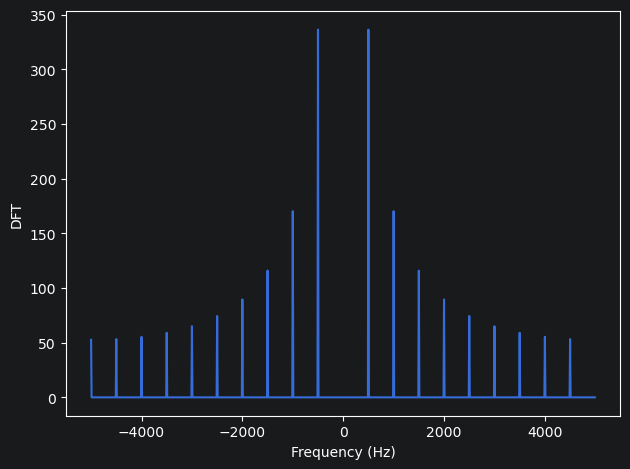

In [93]:
spectrum.plot()
decorate(xlabel='Frequency (Hz)', ylabel='DFT')